## Install and load required packages

In [1]:
# use the correct version of torch!
! pip install torch==2.8.0

# pytorch geometric dependencies:
! pip install torch_geometric

# for gpu installation use this line:
! pip install pyg_lib torch_scatter torch_sparse torch_cluster torch_spline_conv -f https://data.pyg.org/whl/torch-2.8.0+cu128.html

# use the following line instead when running on a cpu only machine:
# ! pip install pyg_lib torch_scatter torch_sparse torch_cluster torch_spline_conv -f https://data.pyg.org/whl/torch-2.8.0+cpu.html

# dependencies for the molecular data
! pip install ase
from torch import nn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 887.9/887.9 MB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 322.4/322.4 MB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 155.6/155.6 MB 11.5 MB/s eta 0:00:00
  Attempting uninstall: triton
    Found existing installation: triton 3.6.0
    Uninstalling triton-3.6.0:
      Successfully uninstalled triton-3.6.0
  Attempting uninstall: nvidia-nccl-cu12
    Found existing installation: nvidia-nccl-cu12 2.27.5
    Uninstalling nvidia-nccl-cu12-2.27.5:
      Successfully uninstalled nvidia-nccl-cu12-2.27.5
  Attempting uninstall: torch
    Found existing installation: torch 2.10.0+cu128
    Uninstalling torch-2.10.0+cu128:
      Successfully uninstalled torch-2.10.0+cu128
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torchaudio 2.10.0+cu128 requires torch==2.10.0, but you have torch 2

In [2]:
import sys

# Define the path to the directory containing utils.py
utils_path = '/kaggle/input/datasets/fahimrayhan/graph-data-for-energy-prediction'

# Add it to sys.path if it's not already there
if utils_path not in sys.path:
    sys.path.append(utils_path)

# Now you can import it like a regular module
import utils

# Optional: If you want to import specific functions
# from utils import your_function_name

In [3]:
import torch
import torch_geometric as pyg

import numpy as np
import matplotlib.pyplot as plt

from scipy.spatial.transform import Rotation



# some helper functions for the lab
from utils import load_toy_data, generate_otf_graph
from coll_data import get_coll_loaders, batch_to_atoms

import ase

In [4]:
# load the two toy graphs.
data1, data2 = load_toy_data()

## Implementing a CGCNN layer

In [5]:
class CGCNNLayer(pyg.nn.MessagePassing):
    def __init__(self, node_fea_dim: int, edge_fea_dim: int):
        # CGCNN aggregates messages with a sum
        super().__init__(aggr="add")

        self.node_fea_dim = node_fea_dim
        self.edge_fea_dim = edge_fea_dim
        in_z = 2 * node_fea_dim + edge_fea_dim  # [h_i, h_j, e]

        # Linear maps for the gate (f) and signal (s) parts in the message
        self.lin_f = torch.nn.Linear(in_z, node_fea_dim, bias=True)
        self.lin_s = torch.nn.Linear(in_z, node_fea_dim, bias=True)

        # BatchNorm before σ and softplus (edge-level BN)
        self.bn_f = torch.nn.BatchNorm1d(node_fea_dim)
        self.bn_s = nn.BatchNorm1d(node_fea_dim)

        # BatchNorm after aggregation (node-level BN)
        self.bn_aggr = nn.BatchNorm1d(node_fea_dim)

        # Activations: gating sigmoid & softplus
        self.act_gate = nn.Sigmoid()
        self.act_signal = nn.Softplus()

    def forward(self, h, edge_index, edge_attr):
        # Compute and aggregate messages m_i = sum_j m_{j->i}
        m = self.propagate(edge_index, h=h, e=edge_attr)  # [num_nodes, d]

        # BN after aggregation, then residual update
        m = self.bn_aggr(m)
        out = h + m
        return out

    def message(self, h_i, h_j, e):
        # z = [h_i, h_j, e] for each edge
        z = torch.cat([h_i, h_j, e], dim=1)  # [num_edges, 2*d + de]

        # Linear → BN → activation for gate and signal
        gate_pre = self.bn_f(self.lin_f(z))
        sig_pre  = self.bn_s(self.lin_s(z))

        gate   = self.act_gate(gate_pre)     # σ(...)
        signal = self.act_signal(sig_pre)    # softplus(...)

        # Element-wise gated message
        return gate * signal

## CGCNN Network

In [6]:
class CGCNN(nn.Module):
    def __init__(self, node_fea_dim, invariant, num_layers, cutoff, max_neighbors):
        super().__init__()

        # Graph generation params
        self.cutoff = cutoff
        self.max_neighbors = max_neighbors
        self.pbc = False  # keep for COLL dataset usage

        # Edge feature choice: 1 -> distance (invariant), 3 -> vector (non-invariant)
        self.edge_fea_dim = 1 if invariant else 3

        # Embedding from atomic number (118 elements) to node features
        self.embed = nn.Embedding(118, node_fea_dim)

        # Stacks of CGCNN layers + per-layer BN + activation
        self.cgcnn_layers = nn.ModuleList([
            CGCNNLayer(node_fea_dim, self.edge_fea_dim) for _ in range(num_layers)
        ])
        self.bn_layers = nn.ModuleList([
            nn.BatchNorm1d(node_fea_dim) for _ in range(num_layers)
        ])
        self.activation = nn.Softplus()

        # Mean pooling (graph-level)
        self.pool = pyg.nn.pool.global_mean_pool

        # Final MLP head → scalar energy
        self.out_mlp = nn.Sequential(
            nn.Linear(node_fea_dim, 2 * node_fea_dim),
            nn.Softplus(),
            nn.Linear(2 * node_fea_dim, 1),
        )

    def forward(self, data):
        # Build graph (on-the-fly)
        edge_index, edge_dist, distance_vec = generate_otf_graph(
            data, self.cutoff, self.max_neighbors, self.pbc
        )
        edge_dist = edge_dist.unsqueeze(-1)
        edge_attr = edge_dist if self.edge_fea_dim == 1 else distance_vec

        # Node features from atomic numbers
        h = self.embed(data.atomic_numbers)  # [num_nodes, node_fea_dim]

        # Stacked CGCNN layers with BN + activation after each layer
        for layer, bn in zip(self.cgcnn_layers, self.bn_layers):
            h = layer(h, edge_index, edge_attr)  # message passing
            h = bn(h)
            h = self.activation(h)

        # Graph-level pooling
        g = self.pool(h, data.batch)          # [num_graphs, node_fea_dim]

        # Final energy prediction
        prediction = self.out_mlp(g)          # [num_graphs, 1]
        return prediction.squeeze(-1)         # [num_graphs]

In [7]:
def transform_and_visualize(data):
    transformed_data = data.clone()
    rot_vec = np.array([1.0, 1.0, 0.0])
    rot_vec = rot_vec / np.linalg.norm(rot_vec)
    rot_angle = np.pi/3
    rotation_matrix = torch.tensor(Rotation.from_rotvec(rot_angle * rot_vec).as_matrix()).float()
    transformed_data.pos = torch.matmul(transformed_data.pos, rotation_matrix)
    fig, ax = plt.subplots(1, 2)
    atoms = batch_to_atoms(data)
    transformed_atoms = batch_to_atoms(transformed_data)

    ase.visualize.plot.plot_atoms(atoms[0], ax[0], rotation=("-75x, 45y, 10z"))
    ase.visualize.plot.plot_atoms(transformed_atoms[0], ax[1], rotation=("-75x, 45y, 10z"))

    ax[0].set_title("Original data")
    ax[1].set_title("Rotated data")
    plt.show()

    return data, transformed_data

Processing...
Done!
Processing...
Done!
Processing...
Done!


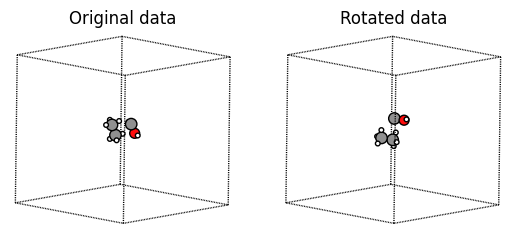

In [8]:
_, loader, _ = get_coll_loaders(5)  # returns train, val, test loaders. For now just using the val loader

data = next(iter(loader))
data, transformed_data = transform_and_visualize(data)

In [9]:
# Reasonable values for cutoff and max_neighbors are 12 [Å] and 30, respectively. For now, number of layers doesn't matter
model_ = CGCNN(32, False, 5, 12, 30)
model_invariant = CGCNN(32, True, 5, 12, 30)

# disable gradient computations here:
with torch.no_grad():

    print("Regular model:")
    print("Output:\t\t\t", model_(data), "\nOutput transformed:\t", model_(transformed_data))

    print()
    print("Invariant model:")
    print("Output:\t\t\t", model_invariant(data), "\nOutput transformed:\t", model_invariant(transformed_data))

Regular model:
Output:			 tensor([-0.8816, -1.0165, -0.8775, -0.8734, -0.8747]) 
Output transformed:	 tensor([-0.8748, -1.0241, -0.8799, -0.8708, -0.8757])

Invariant model:
Output:			 tensor([-0.3225, -0.0738, -0.2781, -0.2732, -0.2728]) 
Output transformed:	 tensor([-0.3225, -0.0738, -0.2781, -0.2732, -0.2728])


## Train a CGCNN model

In [10]:
device = "cuda" # todo: change to cuda if you are using gpu support.

In [11]:
train_loader, val_loader, test_loader = get_coll_loaders(256)

In [12]:
@torch.inference_mode()
def validate(model, loader, device):
    assert not model.training, "Model is in training mode"
    num_samples = 0
    total_sq_error = 0
    total_abs_error = 0

    for i, batch in enumerate(loader):
        batch = batch.to(device)
        batch_size = batch.y.shape[0]
        num_samples += batch_size

        pred = model(batch)
        mae = torch.nn.functional.l1_loss(pred, batch.y)
        mse = torch.nn.functional.mse_loss(pred, batch.y)

        total_sq_error += mse.item()*batch_size
        total_abs_error += mae.item()*batch_size

    avg_mse = total_sq_error / num_samples
    avg_mae = total_abs_error / num_samples
    return avg_mse, avg_mae

def train_and_test(model, optimizer, loss_fn, train_loader, val_loader, num_epochs=10, device="cuda", save_name="best_parameters.pt", test_loader=None):
    model = model.to(device)
    best_val_error = 1e9

    losses = []
    val_errors = []

    for epoch in range(num_epochs):
        model.train(True)

        epoch_losses = []
        for i, batch in enumerate(train_loader):
            optimizer.zero_grad()
            batch = batch.to(device)

            pred = model(batch)
            loss = loss_fn(pred, batch.y)

            loss.backward()
            optimizer.step()
            epoch_losses.append(loss.item())

        mean_epoch_loss = np.mean(epoch_losses)
        print(f"Epoch {epoch+1} training loss: \t {mean_epoch_loss:.4f}")

        # Validation
        model.train(False)
        val_mse, val_mae = validate(model, val_loader, device)
        print(f"Epoch {epoch+1} validation MSE: {val_mse:.4f} \t MAE: {val_mae:.4f}")
        if val_mae < best_val_error:  # we choose MAE as preferred metric
            torch.save(model.state_dict(), save_name)  # save these model parameters
            best_val_error = val_mae

        # store validation error and training loss for visualization later
        val_errors.append((val_mae, val_mse))
        losses.append(mean_epoch_loss)

    print("Training finished!")
    model.train(False)

    if test_loader is not None:
        print("Evaluating on test set")
        model.load_state_dict(torch.load(save_name, weights_only=False))  # load best parameters, based on validation error (early stopping)
        test_mse, test_mae = validate(model, test_loader, device)
        print(f"Final test MSE: {test_mse:.4f}, \t MAE {test_mae:.4f}")

    return losses, val_errors, (test_mse, test_mae)

In [13]:
# Reasonable values for cutoff and max_neighbors are 12 [Å] and 30 max neighbours, respectively.
model_inv = CGCNN(node_fea_dim=32, invariant=True, num_layers=3, cutoff=12, max_neighbors=30)

# choose optimizer and loss function.
optimizer = torch.optim.AdamW(model_inv.parameters(), lr=0.0001)
loss_fn = torch.nn.L1Loss()

# run the training loop.
train, val, test = train_and_test(model_inv, optimizer, loss_fn, train_loader, val_loader, 30, device, "best_parameters_invariant.pt", test_loader)

Epoch 1 training loss: 	 1.0714
Epoch 1 validation MSE: 0.1042 	 MAE: 0.2043
Epoch 2 training loss: 	 0.1963
Epoch 2 validation MSE: 0.0947 	 MAE: 0.1926
Epoch 3 training loss: 	 0.1881
Epoch 3 validation MSE: 0.0931 	 MAE: 0.1944
Epoch 4 training loss: 	 0.1833
Epoch 4 validation MSE: 0.0879 	 MAE: 0.1961
Epoch 5 training loss: 	 0.1780
Epoch 5 validation MSE: 0.0796 	 MAE: 0.1757
Epoch 6 training loss: 	 0.1749
Epoch 6 validation MSE: 0.0779 	 MAE: 0.1730
Epoch 7 training loss: 	 0.1717
Epoch 7 validation MSE: 0.0801 	 MAE: 0.1822
Epoch 8 training loss: 	 0.1694
Epoch 8 validation MSE: 0.0722 	 MAE: 0.1669
Epoch 9 training loss: 	 0.1677
Epoch 9 validation MSE: 0.0719 	 MAE: 0.1721
Epoch 10 training loss: 	 0.1652
Epoch 10 validation MSE: 0.0681 	 MAE: 0.1627
Epoch 11 training loss: 	 0.1641
Epoch 11 validation MSE: 0.0702 	 MAE: 0.1730
Epoch 12 training loss: 	 0.1621
Epoch 12 validation MSE: 0.0674 	 MAE: 0.1639
Epoch 13 training loss: 	 0.1609
Epoch 13 validation MSE: 0.0646 	 MAE

In [14]:
# use same setup as before, only change type of edge features
model = CGCNN(node_fea_dim=32, invariant=False, num_layers=3, cutoff=12, max_neighbors=30)

optimizer = torch.optim.AdamW(model.parameters(), lr=0.0001)
loss_fn = torch.nn.L1Loss()

train_ninv, val_ninv, test_ninv = train_and_test(model, optimizer, loss_fn, train_loader, val_loader, 30, device, "best_parameters_non_invariant.pt", test_loader)

Epoch 1 training loss: 	 1.0637
Epoch 1 validation MSE: 0.1110 	 MAE: 0.2127
Epoch 2 training loss: 	 0.2062
Epoch 2 validation MSE: 0.1038 	 MAE: 0.2044
Epoch 3 training loss: 	 0.2012
Epoch 3 validation MSE: 0.1003 	 MAE: 0.2007
Epoch 4 training loss: 	 0.1982
Epoch 4 validation MSE: 0.0977 	 MAE: 0.1993
Epoch 5 training loss: 	 0.1959
Epoch 5 validation MSE: 0.0946 	 MAE: 0.1956
Epoch 6 training loss: 	 0.1938
Epoch 6 validation MSE: 0.0927 	 MAE: 0.1942
Epoch 7 training loss: 	 0.1915
Epoch 7 validation MSE: 0.0908 	 MAE: 0.1911
Epoch 8 training loss: 	 0.1897
Epoch 8 validation MSE: 0.0884 	 MAE: 0.1893
Epoch 9 training loss: 	 0.1878
Epoch 9 validation MSE: 0.0871 	 MAE: 0.1887
Epoch 10 training loss: 	 0.1862
Epoch 10 validation MSE: 0.0860 	 MAE: 0.1874
Epoch 11 training loss: 	 0.1852
Epoch 11 validation MSE: 0.0892 	 MAE: 0.1940
Epoch 12 training loss: 	 0.1838
Epoch 12 validation MSE: 0.0838 	 MAE: 0.1840
Epoch 13 training loss: 	 0.1827
Epoch 13 validation MSE: 0.0827 	 MAE

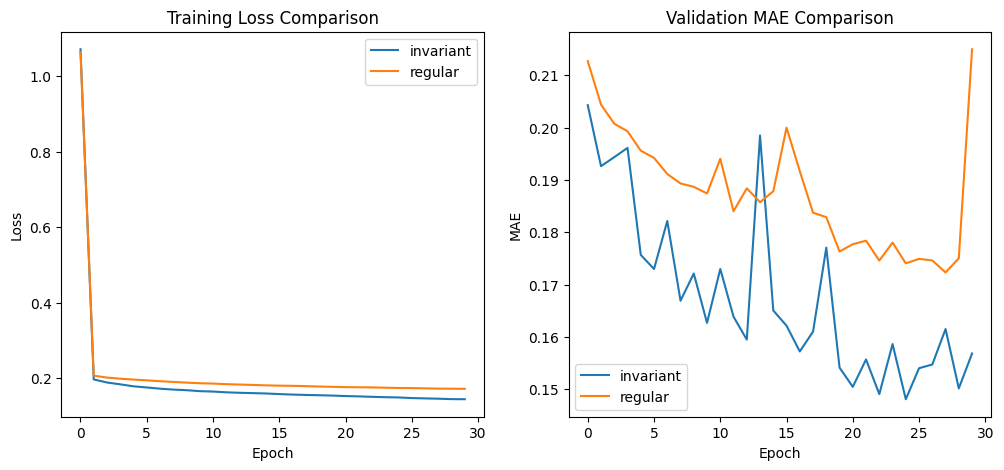

In [15]:
# plot the training loss and validation MAE curves for both models to compare their performance.
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)

plt.plot(train, label="invariant")
plt.plot(train_ninv, label="regular")

plt.legend()
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss Comparison")

plt.subplot(1, 2, 2)
plt.plot([x[0] for x in val], label="invariant")
plt.plot([x[0] for x in val_ninv], label="regular")

plt.legend()
plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.title("Validation MAE Comparison")
plt.show()